## Problem Statement

- This project contains information about loan applicants, including their application details and previous credit and payment history. The bureau dataset contains applicants' previous credit information from different financial institutions, while POS_CASH_balance contains monthly balance information for previous Home Credit loans.

- The credit_card_balance dataset contains monthly credit-card balance information, and the previous_application dataset contains applicants' previous loan applications within Home Credit. The installments_payments dataset contains applicants' previous installment payment history.

-  Using this information, the objective is to predict whether an applicant is likely to default on a loan. The target variable contains two classes: 0 represents a non-defaulter, while 1 represents a defaulter.


## Objective

- To analyze the available applicant, credit, previous application, and payment-history data to identify factors associated with loan default.

- To preprocess and integrate the relevant information from the available datasets to create meaningful features for prediction.

- To develop classification models to predict whether an applicant is likely to default on a loan.

- To compare the performance of multiple classification models using appropriate evaluation metrics and identify the best-performing model.

- To use the model results to identify factors and customer segments associated with loan-default risk and provide recommendations relevant to lending decisions.

## Dataset Description

| Dataset                     | What does it contain?                                                          | What does one row represent?                                         |
| --------------------------- | ------------------------------------------------------------------------------ | -------------------------------------------------------------------- |
| `application_train.csv`     | Applicant/application information                                              | One loan application in our dataset                                  |
| `bureau.csv`                | Previous credit information from other financial institutions                  | One previous credit record reported by another financial institution |
| `bureau_balance.csv`        | Monthly balance information for previous credits reported to the credit bureau | One month's history for a previous credit                            |
| `POS_CASH_balance.csv`      | Monthly balance information for previous Home Credit loans                     | One month's history for a previous Home Credit loan                  |
| `credit_card_balance.csv`   | Monthly credit-card balance information                                        | One month's history of a previous Home Credit credit card            |
| `previous_application.csv`  | Information about previous applications to Home Credit                         | One previous loan application related to a customer in our dataset   |
| `installments_payments.csv` | Previous installment payment information                                       | One installment payment record                                       |


## Importing all the Required Libraries

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [6]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

## Data Loading

In [7]:
application_train = pd.read_csv("application_train.csv")

In [8]:
bureau_balance = pd.read_csv('bureau_balance.csv')

In [9]:
previous_application = pd.read_csv('previous_application.csv')

In [10]:
pos_cash = pd.read_csv('POS_CASH_balance.csv')

In [11]:
credit_card = pd.read_csv('credit_card_balance.csv')

In [12]:
installments = pd.read_csv('installments_payments.csv')

## Feature Engineering: Merging Auxiliary Datasets

Each auxiliary table below is aggregated to one row per applicant (`SK_ID_CURR`) and merged onto `application_train`, so the final model can use each applicant's full credit history — not just their current application.

### 1. Bureau & Bureau Balance (previous credit history from other institutions)

In [13]:
bureau_balance['STATUS'].value_counts()

STATUS
C    13646993
0     7499507
X     5810482
1      242347
5       62406
2       23419
3        8924
4        5847
Name: count, dtype: int64

In [14]:
status_map = {'C': 0, 'X': 0, '0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5}
bureau_balance['STATUS_NUM'] = bureau_balance['STATUS'].map(status_map)

In [15]:
bureau_balance_agg = bureau_balance.groupby('SK_ID_BUREAU').agg(
    MONTHS_COUNT=('MONTHS_BALANCE', 'count'),
    MAX_DELINQUENCY=('STATUS_NUM', 'max')
).reset_index()

In [16]:
bureau_balance_agg.shape

(817395, 3)

In [17]:
bureau = pd.read_csv('bureau.csv')
bureau = bureau.merge(bureau_balance_agg, on='SK_ID_BUREAU', how='left')

In [18]:
bureau.shape

(1716428, 19)

In [19]:
bureau.head()

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY,MONTHS_COUNT,MAX_DELINQUENCY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN,NaN,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN,NaN,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN,NaN,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN,NaN,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN,NaN,NaN


In [20]:
bureau.isnull().sum()

SK_ID_CURR                      0
SK_ID_BUREAU                    0
CREDIT_ACTIVE                   0
CREDIT_CURRENCY                 0
DAYS_CREDIT                     0
CREDIT_DAY_OVERDUE              0
DAYS_CREDIT_ENDDATE        105553
DAYS_ENDDATE_FACT          633653
AMT_CREDIT_MAX_OVERDUE    1124488
CNT_CREDIT_PROLONG              0
AMT_CREDIT_SUM                 13
AMT_CREDIT_SUM_DEBT        257669
AMT_CREDIT_SUM_LIMIT       591780
AMT_CREDIT_SUM_OVERDUE          0
CREDIT_TYPE                     0
DAYS_CREDIT_UPDATE              0
AMT_ANNUITY               1226791
MONTHS_COUNT               942074
MAX_DELINQUENCY            942074
dtype: int64

In [21]:
bureau_agg = bureau.groupby('SK_ID_CURR').agg(
    BUREAU_CREDIT_COUNT=('SK_ID_BUREAU', 'count'),
    BUREAU_TOTAL_DEBT=('AMT_CREDIT_SUM_DEBT', 'sum'),
    BUREAU_TOTAL_OVERDUE=('AMT_CREDIT_SUM_OVERDUE', 'sum'),
    BUREAU_MAX_DELINQUENCY=('MAX_DELINQUENCY', 'max'),
    BUREAU_TOTAL_CREDIT=('AMT_CREDIT_SUM', 'sum')
).reset_index()

In [22]:
bureau_agg.shape

(305811, 6)

In [23]:
bureau_agg.head()

,SK_ID_CURR,BUREAU_CREDIT_COUNT,BUREAU_TOTAL_DEBT,BUREAU_TOTAL_OVERDUE,BUREAU_MAX_DELINQUENCY,BUREAU_TOTAL_CREDIT
0,100001,7,596686.5,0.0,1.0,1453365.000
1,100002,8,245781.0,0.0,1.0,865055.565
2,100003,4,0.0,0.0,NaN,1017400.500
3,100004,2,0.0,0.0,NaN,189037.800
4,100005,3,568408.5,0.0,0.0,657126.000


In [24]:
application_train = application_train.merge(bureau_agg, on='SK_ID_CURR', how='left')

In [25]:
bureau_cols = ['BUREAU_CREDIT_COUNT', 'BUREAU_TOTAL_DEBT', 'BUREAU_TOTAL_OVERDUE', 'BUREAU_MAX_DELINQUENCY', 'BUREAU_TOTAL_CREDIT']
application_train[bureau_cols] = application_train[bureau_cols].fillna(0)

In [26]:
application_train.shape

(307511, 127)

In [27]:
application_train[bureau_cols].isnull().sum()

BUREAU_CREDIT_COUNT       0
BUREAU_TOTAL_DEBT         0
BUREAU_TOTAL_OVERDUE      0
BUREAU_MAX_DELINQUENCY    0
BUREAU_TOTAL_CREDIT       0
dtype: int64

### 2. Previous Application (applicant's own history with Home Credit)

In [28]:
previous_application.head()

,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,RATE_INTEREST_PRIMARY,RATE_INTEREST_PRIVILEGED,NAME_CASH_LOAN_PURPOSE,NAME_CONTRACT_STATUS,DAYS_DECISION,NAME_PAYMENT_TYPE,CODE_REJECT_REASON,NAME_TYPE_SUITE,NAME_CLIENT_TYPE,NAME_GOODS_CATEGORY,NAME_PORTFOLIO,NAME_PRODUCT_TYPE,CHANNEL_TYPE,SELLERPLACE_AREA,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,Y,1,0.0,0.182832,0.867336,XAP,Approved,-73,Cash through the bank,XAP,NaN,Repeater,Mobile,POS,XNA,Country-wide,35,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-164,XNA,XAP,Unaccompanied,Repeater,XNA,Cash,x-sell,Contact center,-1,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-301,Cash through the bank,XAP,"Spouse, partner",Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,Y,1,NaN,NaN,NaN,XNA,Approved,-512,Cash through the bank,XAP,NaN,Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,Y,1,NaN,NaN,NaN,Repairs,Refused,-781,Cash through the bank,HC,NaN,Repeater,XNA,Cash,walk-in,Credit and cash offices,-1,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
previous_application.shape

(1670214, 37)

In [30]:
previous_application['IS_APPROVED'] = (previous_application['NAME_CONTRACT_STATUS'] == 'Approved').astype(int)
previous_application['IS_REFUSED'] = (previous_application['NAME_CONTRACT_STATUS'] == 'Refused').astype(int)

In [31]:
previous_application_agg = previous_application.groupby('SK_ID_CURR').agg(
    PREV_APP_COUNT=('SK_ID_PREV', 'count'),
    PREV_APPROVAL_RATE=('IS_APPROVED', 'mean'),
    PREV_REFUSED_COUNT=('IS_REFUSED', 'sum'),
    PREV_AMT_CREDIT_MEAN=('AMT_CREDIT', 'mean'),
    PREV_AMT_APPLICATION_MEAN=('AMT_APPLICATION', 'mean')
).reset_index()

In [32]:
previous_application_agg.shape

(338857, 6)

In [33]:
previous_application_agg.head()

,SK_ID_CURR,PREV_APP_COUNT,PREV_APPROVAL_RATE,PREV_REFUSED_COUNT,PREV_AMT_CREDIT_MEAN,PREV_AMT_APPLICATION_MEAN
0,100001,1,1.0,0,23787.00,24835.50
1,100002,1,1.0,0,179055.00,179055.00
2,100003,3,1.0,0,484191.00,435436.50
3,100004,1,1.0,0,20106.00,24282.00
4,100005,2,0.5,0,20076.75,22308.75


In [34]:
application_train = application_train.merge(previous_application_agg, on='SK_ID_CURR', how='left')

count_cols = ['PREV_APP_COUNT', 'PREV_REFUSED_COUNT']
application_train[count_cols] = application_train[count_cols].fillna(0)

rate_cols = ['PREV_APPROVAL_RATE', 'PREV_AMT_CREDIT_MEAN', 'PREV_AMT_APPLICATION_MEAN']
application_train[rate_cols] = application_train[rate_cols].fillna(application_train[rate_cols].median())

In [35]:
application_train.shape

(307511, 132)

### 3. POS_CASH_balance (monthly point-of-sale/cash loan history)

In [36]:
pos_cash.head()

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1715348,367990,-33,36.0,35.0,Active,0,0
2,1784872,397406,-32,12.0,9.0,Active,0,0
3,1903291,269225,-35,48.0,42.0,Active,0,0
4,2341044,334279,-35,36.0,35.0,Active,0,0


In [37]:
pos_cash.shape

(10001358, 8)

In [38]:
pos_cash['IS_LATE'] = (pos_cash['SK_DPD'] > 0).astype(int)

In [39]:
pos_cash_agg = pos_cash.groupby('SK_ID_CURR').agg(
    POS_COUNT=('SK_ID_PREV', 'count'),
    POS_MAX_DPD=('SK_DPD', 'max'),
    POS_LATE_COUNT=('IS_LATE', 'sum')
).reset_index()

In [40]:
pos_cash_agg.shape

(337252, 4)

In [41]:
pos_cash_agg.head()

,SK_ID_CURR,POS_COUNT,POS_MAX_DPD,POS_LATE_COUNT
0,100001,9,7,1
1,100002,19,0,0
2,100003,28,0,0
3,100004,4,0,0
4,100005,11,0,0


In [42]:
application_train = application_train.merge(pos_cash_agg, on='SK_ID_CURR', how='left')

pos_cols = ['POS_COUNT', 'POS_MAX_DPD', 'POS_LATE_COUNT']
application_train[pos_cols] = application_train[pos_cols].fillna(0)

In [43]:
application_train.shape

(307511, 135)

In [44]:
application_train[pos_cols].isnull().sum()

POS_COUNT         0
POS_MAX_DPD       0
POS_LATE_COUNT    0
dtype: int64

### 4. Credit Card Balance (monthly credit card usage history)

In [45]:
credit_card.head()

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,AMT_PAYMENT_CURRENT,AMT_PAYMENT_TOTAL_CURRENT,AMT_RECEIVABLE_PRINCIPAL,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,1800.0,1800.0,0.000,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,2250.0,2250.0,60175.080,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,2250.0,2250.0,26926.425,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,11925.0,11925.0,224949.285,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,27000.0,27000.0,443044.395,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0


In [46]:
credit_card.shape

(3840312, 23)

In [47]:
credit_card['UTILIZATION'] = credit_card['AMT_BALANCE'] / credit_card['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)

In [48]:
credit_card_agg = credit_card.groupby('SK_ID_CURR').agg(
    CC_COUNT=('SK_ID_PREV', 'count'),
    CC_AVG_BALANCE=('AMT_BALANCE', 'mean'),
    CC_AVG_LIMIT=('AMT_CREDIT_LIMIT_ACTUAL', 'mean'),
    CC_AVG_UTILIZATION=('UTILIZATION', 'mean'),
    CC_MAX_DPD=('SK_DPD', 'max')
).reset_index()

In [49]:
application_train = application_train.merge(credit_card_agg, on='SK_ID_CURR', how='left')

cc_zero_cols = ['CC_COUNT', 'CC_MAX_DPD']
application_train[cc_zero_cols] = application_train[cc_zero_cols].fillna(0)

cc_median_cols = ['CC_AVG_BALANCE', 'CC_AVG_LIMIT', 'CC_AVG_UTILIZATION']
application_train[cc_median_cols] = application_train[cc_median_cols].fillna(application_train[cc_median_cols].median())

In [50]:
application_train.shape

(307511, 140)

### 5. Installments Payments (actual repayment history)

In [51]:
installments.head()

,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585


In [52]:
installments.shape

(13605401, 8)

In [53]:
installments['PAYMENT_SHORTFALL'] = installments['AMT_INSTALMENT'] - installments['AMT_PAYMENT']

In [54]:
installments['PAYMENT_LATENESS'] = installments['DAYS_ENTRY_PAYMENT'] - installments['DAYS_INSTALMENT']

In [55]:
installments_agg = installments.groupby('SK_ID_CURR').agg(
    INST_COUNT=('SK_ID_PREV', 'count'),
    INST_AVG_SHORTFALL=('PAYMENT_SHORTFALL', 'mean'),
    INST_MAX_SHORTFALL=('PAYMENT_SHORTFALL', 'max'),
    INST_AVG_LATENESS=('PAYMENT_LATENESS', 'mean'),
    INST_MAX_LATENESS=('PAYMENT_LATENESS', 'max')
).reset_index()

In [56]:
application_train = application_train.merge(installments_agg, on='SK_ID_CURR', how='left')

inst_zero_cols = ['INST_COUNT']
application_train[inst_zero_cols] = application_train[inst_zero_cols].fillna(0)

inst_median_cols = ['INST_AVG_SHORTFALL', 'INST_MAX_SHORTFALL', 'INST_AVG_LATENESS', 'INST_MAX_LATENESS']
application_train[inst_median_cols] = application_train[inst_median_cols].fillna(application_train[inst_median_cols].median())

In [57]:
application_train.shape

(307511, 145)

## Final Combined Dataset Overview

In [58]:
application_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 145 entries, SK_ID_CURR to INST_MAX_LATENESS
dtypes: float64(88), int64(41), object(16)
memory usage: 340.2+ MB


In [59]:
column_info = pd.DataFrame({
    "Column": application_train.columns.to_list(),
    "Data_Type": application_train.dtypes.to_list()
})
column_info

,Column,Data_Type
0,SK_ID_CURR,int64
1,TARGET,int64
2,NAME_CONTRACT_TYPE,object
3,CODE_GENDER,object
4,FLAG_OWN_CAR,object
5,FLAG_OWN_REALTY,object
6,CNT_CHILDREN,int64
7,AMT_INCOME_TOTAL,float64
8,AMT_CREDIT,float64
9,AMT_ANNUITY,float64


In [60]:
application_train.dtypes.value_counts()

float64    88
int64      41
object     16
Name: count, dtype: int64

In [61]:
application_train.dtypes[application_train.dtypes == "object"]

NAME_CONTRACT_TYPE            object
CODE_GENDER                   object
FLAG_OWN_CAR                  object
FLAG_OWN_REALTY               object
NAME_TYPE_SUITE               object
NAME_INCOME_TYPE              object
NAME_EDUCATION_TYPE           object
NAME_FAMILY_STATUS            object
NAME_HOUSING_TYPE             object
OCCUPATION_TYPE               object
WEEKDAY_APPR_PROCESS_START    object
ORGANIZATION_TYPE             object
FONDKAPREMONT_MODE            object
HOUSETYPE_MODE                object
WALLSMATERIAL_MODE            object
EMERGENCYSTATE_MODE           object
dtype: object

In [62]:
application_train["TARGET"].value_counts()

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [63]:
application_train["TARGET"].value_counts(normalize=True)

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

### Target Variable Distribution

- The target variable contains two classes:
    - Class 0 represents a non-defaulter.
    - Class 1 represents a defaulter.
- Class 0 accounts for approximately 91.93% of the total data.
- Class 1 accounts for approximately 8.07% of the total data.
- The distribution shows that the target variable is imbalanced, with a much larger proportion of non-defaulters than defaulters.

### Missing Value Analysis

- Several columns contain a high proportion of missing values.
- 41 columns have more than 50% missing values.
- The highest missing-value percentages are found mainly among property-related features such as COMMONAREA, LIVINGAPARTMENTS, NONLIVINGAPARTMENTS, and YEARS_BUILD.
- These columns will not be removed solely based on their missing-value percentage; their relevance and relationship with the target will be considered before making a preprocessing decision.

In [64]:
missing_summary = pd.DataFrame({
    "column":application_train.columns.to_list(),
    "Missing_Values":application_train.isnull().sum().to_list(),
    "Missing_Percentage":((application_train.isnull().sum()/application_train.shape[0])*100).to_list()
})

In [65]:
missing_summary.sort_values("Missing_Percentage",ascending=False)

,column,Missing_Values,Missing_Percentage
48,COMMONAREA_AVG,214865,69.872297
62,COMMONAREA_MODE,214865,69.872297
76,COMMONAREA_MEDI,214865,69.872297
70,NONLIVINGAPARTMENTS_MODE,213514,69.432963
84,NONLIVINGAPARTMENTS_MEDI,213514,69.432963
56,NONLIVINGAPARTMENTS_AVG,213514,69.432963
86,FONDKAPREMONT_MODE,210295,68.386172
68,LIVINGAPARTMENTS_MODE,210199,68.354953
54,LIVINGAPARTMENTS_AVG,210199,68.354953
82,LIVINGAPARTMENTS_MEDI,210199,68.354953


In [66]:
missing_summary[missing_summary["Missing_Percentage"]==0].shape

(78, 3)

In [67]:
missing_data = missing_summary[missing_summary["Missing_Percentage"] > 0]

In [68]:
missing_data = missing_data.sort_values(
    "Missing_Percentage",
    ascending=False
)

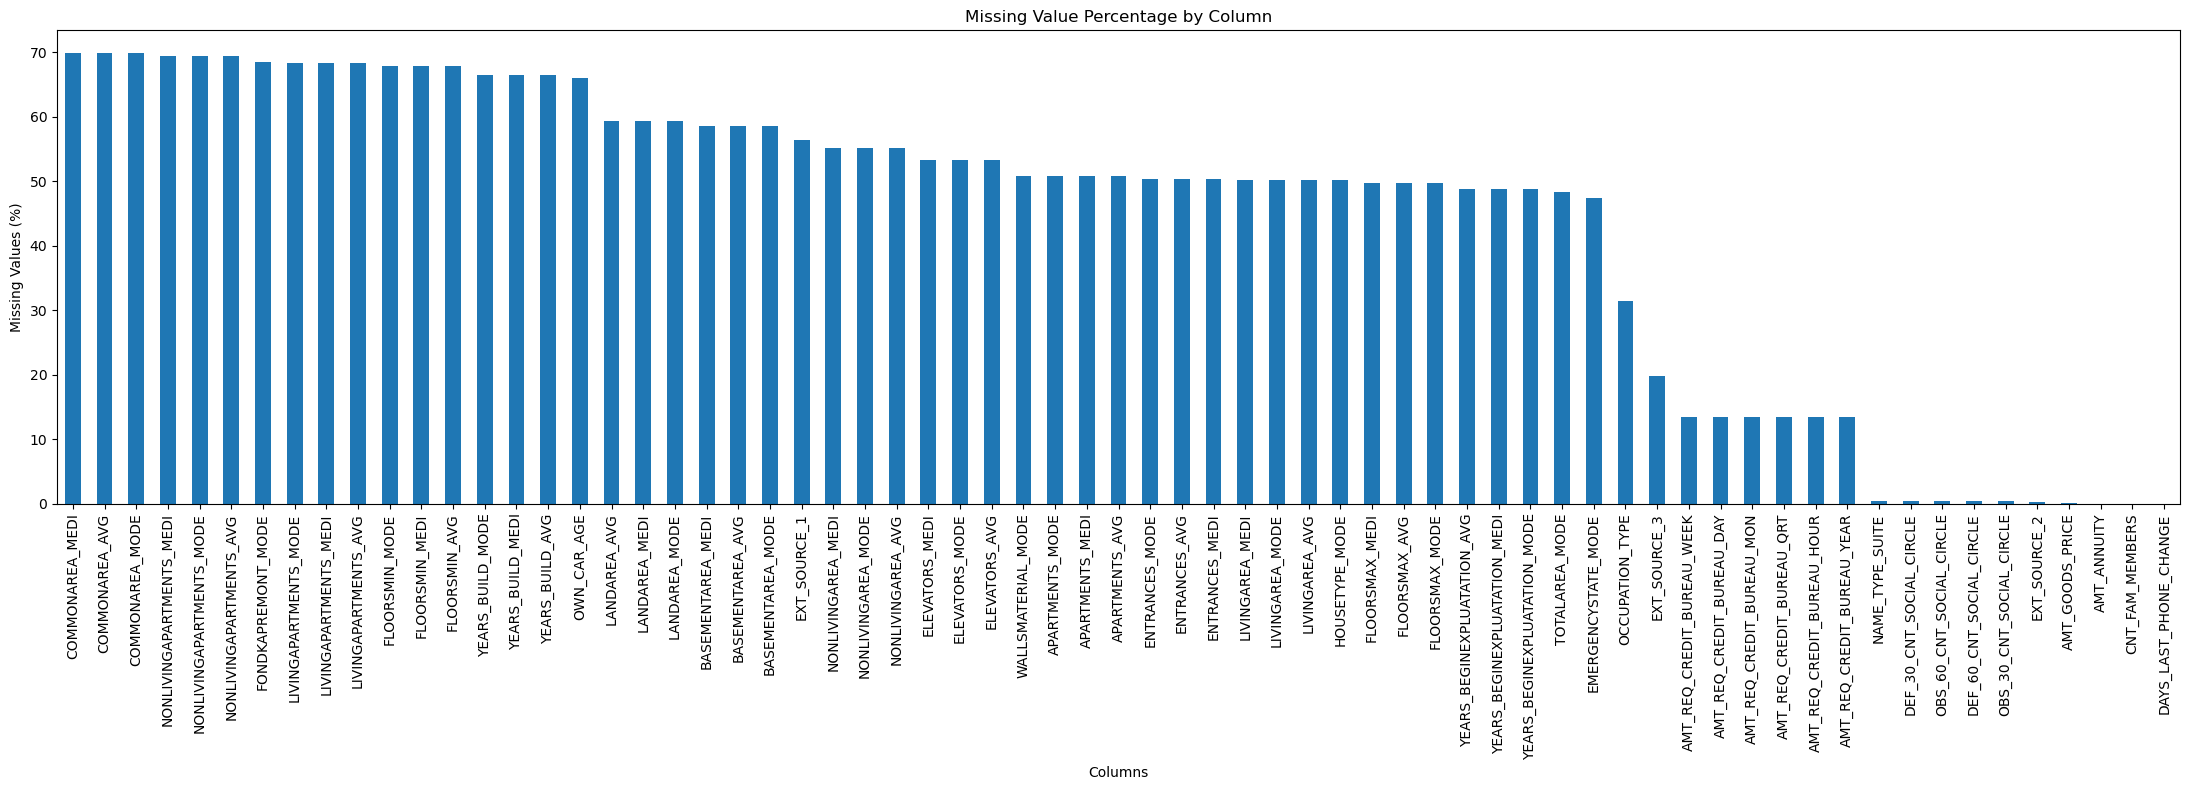

In [69]:
missing_data.plot.bar(
    x="column",
    y="Missing_Percentage",
    figsize=(22, 8),
    legend=False
)

plt.xticks(rotation=90)
plt.tight_layout()
plt.ylabel("Missing Values (%)")
plt.xlabel("Columns")
plt.title("Missing Value Percentage by Column")
plt.tight_layout()
plt.show()

In [70]:
application_train.duplicated().sum()

np.int64(0)

### Handling the DAYS_EMPLOYED Anomaly

- `DAYS_EMPLOYED` contained an anomalous placeholder value of **365243** (equivalent to ~1000 years), which is not a valid employment duration.
- This value appeared in **55,374 rows (~18% of the dataset)** — too large a portion to drop, and likely meaningful rather than random noise.
- Cross-checking against `NAME_INCOME_TYPE` showed the anomaly is almost entirely tied to **Pensioners (55,352 rows)** and a small number of **Unemployed (22 rows)** applicants — i.e. people with no current job, for whom the source system appears to have used this placeholder instead of a null value.
- **Approach taken:**
  1. Created a new binary flag column, `DAYS_EMPLOYED_ANOM`, marking which rows originally had the placeholder — preserving this as a potential predictive signal (income type / employment status is often relevant to credit risk).
  2. Replaced the placeholder value in `DAYS_EMPLOYED` itself with `NaN`, since 365243 is not a genuine value and would otherwise distort any statistics or model trained on this column.
- After the fix, `DAYS_EMPLOYED` ranges realistically from -17912 to 0 with no remaining anomalies.

In [71]:
application_train["DAYS_EMPLOYED"].unique()

array([  -637,  -1188,   -225, ..., -12971, -11084,  -8694],
      shape=(12574,))

In [72]:
application_train["DAYS_EMPLOYED"].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [73]:
(application_train["DAYS_EMPLOYED"] == 365243).sum()

np.int64(55374)

In [74]:
application_train.loc[application_train["DAYS_EMPLOYED"] == 365243, "NAME_INCOME_TYPE"].value_counts()

NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

In [75]:
application_train["DAYS_EMPLOYED_ANOM"] = (application_train["DAYS_EMPLOYED"] == 365243).astype(int)

In [76]:
(application_train["DAYS_EMPLOYED_ANOM"] == 1).sum()

np.int64(55374)

In [77]:
application_train["DAYS_EMPLOYED"] = application_train["DAYS_EMPLOYED"].replace(365243,np.nan)

In [78]:
application_train["DAYS_EMPLOYED"].describe()

count    252137.000000
mean      -2384.169325
std        2338.360162
min      -17912.000000
25%       -3175.000000
50%       -1648.000000
75%        -767.000000
max           0.000000
Name: DAYS_EMPLOYED, dtype: float64

## Missing Value Imputation

In [79]:
missing_data[missing_data["Missing_Percentage"] > 40]

,column,Missing_Values,Missing_Percentage
76,COMMONAREA_MEDI,214865,69.872297
48,COMMONAREA_AVG,214865,69.872297
62,COMMONAREA_MODE,214865,69.872297
84,NONLIVINGAPARTMENTS_MEDI,213514,69.432963
70,NONLIVINGAPARTMENTS_MODE,213514,69.432963
56,NONLIVINGAPARTMENTS_AVG,213514,69.432963
86,FONDKAPREMONT_MODE,210295,68.386172
68,LIVINGAPARTMENTS_MODE,210199,68.354953
82,LIVINGAPARTMENTS_MEDI,210199,68.354953
54,LIVINGAPARTMENTS_AVG,210199,68.354953


In [80]:
application_train.head(7)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,BUREAU_CREDIT_COUNT,BUREAU_TOTAL_DEBT,BUREAU_TOTAL_OVERDUE,BUREAU_MAX_DELINQUENCY,BUREAU_TOTAL_CREDIT,PREV_APP_COUNT,PREV_APPROVAL_RATE,PREV_REFUSED_COUNT,PREV_AMT_CREDIT_MEAN,PREV_AMT_APPLICATION_MEAN,POS_COUNT,POS_MAX_DPD,POS_LATE_COUNT,CC_COUNT,CC_AVG_BALANCE,CC_AVG_LIMIT,CC_AVG_UTILIZATION,CC_MAX_DPD,INST_COUNT,INST_AVG_SHORTFALL,INST_MAX_SHORTFALL,INST_AVG_LATENESS,INST_MAX_LATENESS,DAYS_EMPLOYED_ANOM
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637.0,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0,8.0,245781.0,0.0,1.0,865055.565,1.0,1.000000,0.0,179055.000000,179055.000000,19.0,0.0,0.0,0.0,26793.606316,149727.272727,0.253387,0.0,19.0,0.000000,0.000,-20.421053,-12.0,0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188.0,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0

In [81]:
application_train[["APARTMENTS_AVG", "APARTMENTS_MODE", "APARTMENTS_MEDI"]].isnull().sum()

APARTMENTS_AVG     156061
APARTMENTS_MODE    156061
APARTMENTS_MEDI    156061
dtype: int64

In [82]:
application_train.isnull().sum().sum()

np.int64(9207839)

In [83]:
numeric_cols = application_train.select_dtypes(include=['int64','float64']).columns

In [84]:
application_train[numeric_cols] = application_train[numeric_cols].fillna(application_train[numeric_cols].median())

In [85]:
application_train[numeric_cols].isnull().sum().sum()

np.int64(0)

In [86]:
obj_cols = application_train.select_dtypes(include='object').columns

In [87]:
application_train[obj_cols] = application_train[obj_cols].fillna(application_train[obj_cols].mode().iloc[0])

In [88]:
application_train[obj_cols].isnull().sum().sum()

np.int64(0)

In [89]:
application_train.isnull().sum().sum()

np.int64(0)

## Feature Engineering: Applicant Age

In [90]:
application_train["AGE_YEARS"] = (application_train['DAYS_BIRTH'].abs())/365

C:\Users\HP\AppData\Local\Temp\ipykernel_26548\28638925.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  application_train["AGE_YEARS"] = (application_train['DAYS_BIRTH'].abs())/365


In [91]:
application_train["AGE_YEARS"].describe()

count    307511.000000
mean         43.936973
std          11.956133
min          20.517808
25%          34.008219
50%          43.150685
75%          53.923288
max          69.120548
Name: AGE_YEARS, dtype: float64

## Exploratory Data Analysis: Numeric Features vs Target

<Axes: xlabel='TARGET', ylabel='AGE_YEARS'>

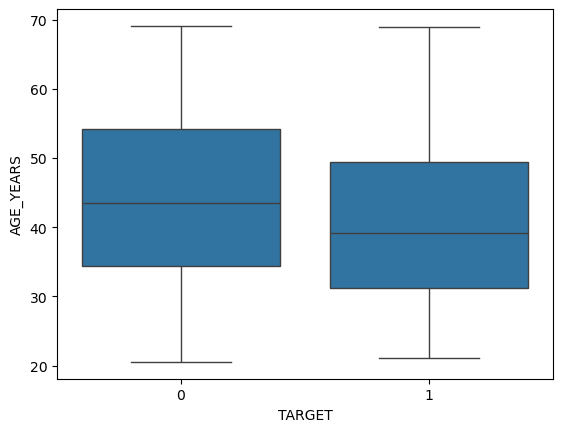

In [92]:
sns.boxplot(application_train,x = 'TARGET',y = 'AGE_YEARS')

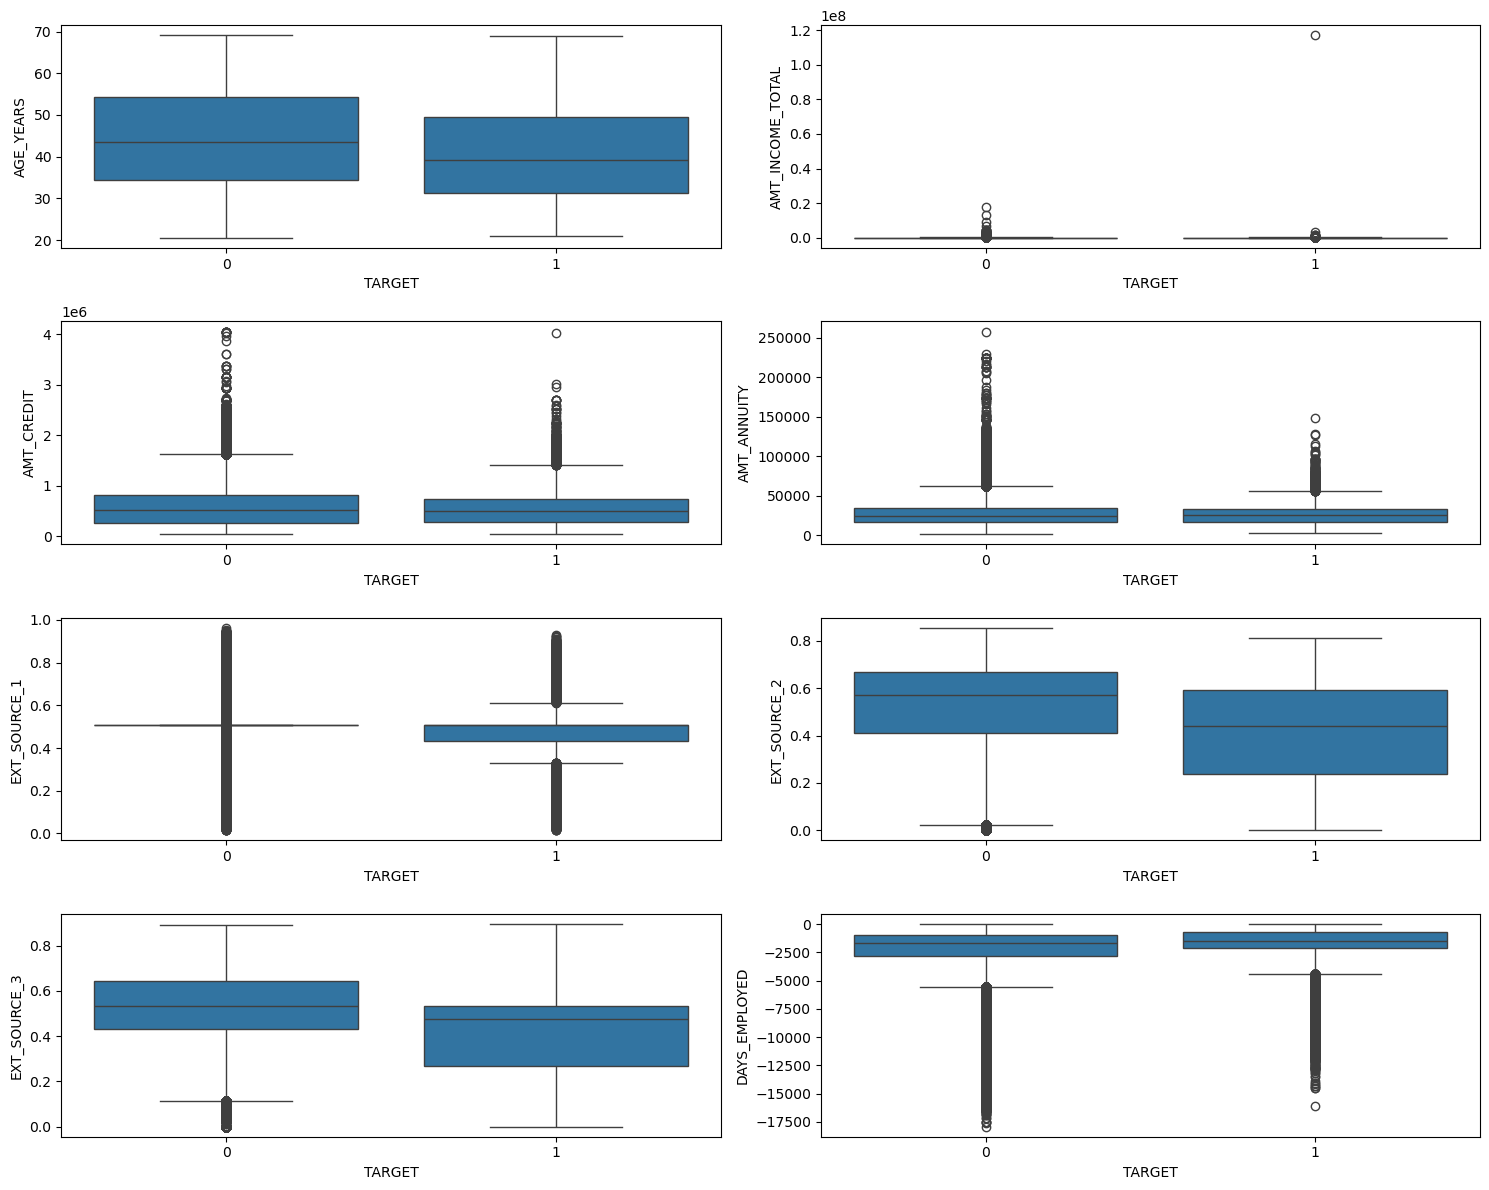

In [93]:
list1=['AGE_YEARS','AMT_INCOME_TOTAL','AMT_CREDIT','AMT_ANNUITY','EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3','DAYS_EMPLOYED']
fig, axes = plt.subplots(4, 2, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(list1):
    sns.boxplot(data=application_train, x="TARGET", y=col, ax=axes[i])
plt.tight_layout()
plt.show()

## Exploratory Data Analysis: Categorical Features vs Target

In [94]:
pd.crosstab(application_train['NAME_EDUCATION_TYPE'], application_train['TARGET'], normalize='index')

TARGET,0,1
NAME_EDUCATION_TYPE,,
Academic degree,0.981707,0.018293
Higher education,0.946449,0.053551
Incomplete higher,0.915150,0.084850
Lower secondary,0.890723,0.109277
Secondary / secondary special,0.910601,0.089399


In [95]:
pd.crosstab(application_train['NAME_INCOME_TYPE'], application_train['TARGET'], normalize='index')

TARGET,0,1
NAME_INCOME_TYPE,,
Businessman,1.000000,0.000000
Commercial associate,0.925157,0.074843
Maternity leave,0.600000,0.400000
Pensioner,0.946136,0.053864
State servant,0.942450,0.057550
Student,1.000000,0.000000
Unemployed,0.636364,0.363636
Working,0.904115,0.095885


In [96]:
pd.crosstab(application_train['CODE_GENDER'], application_train['TARGET'], normalize='index')

TARGET,0,1
CODE_GENDER,,
F,0.930007,0.069993
M,0.898581,0.101419
XNA,1.000000,0.000000


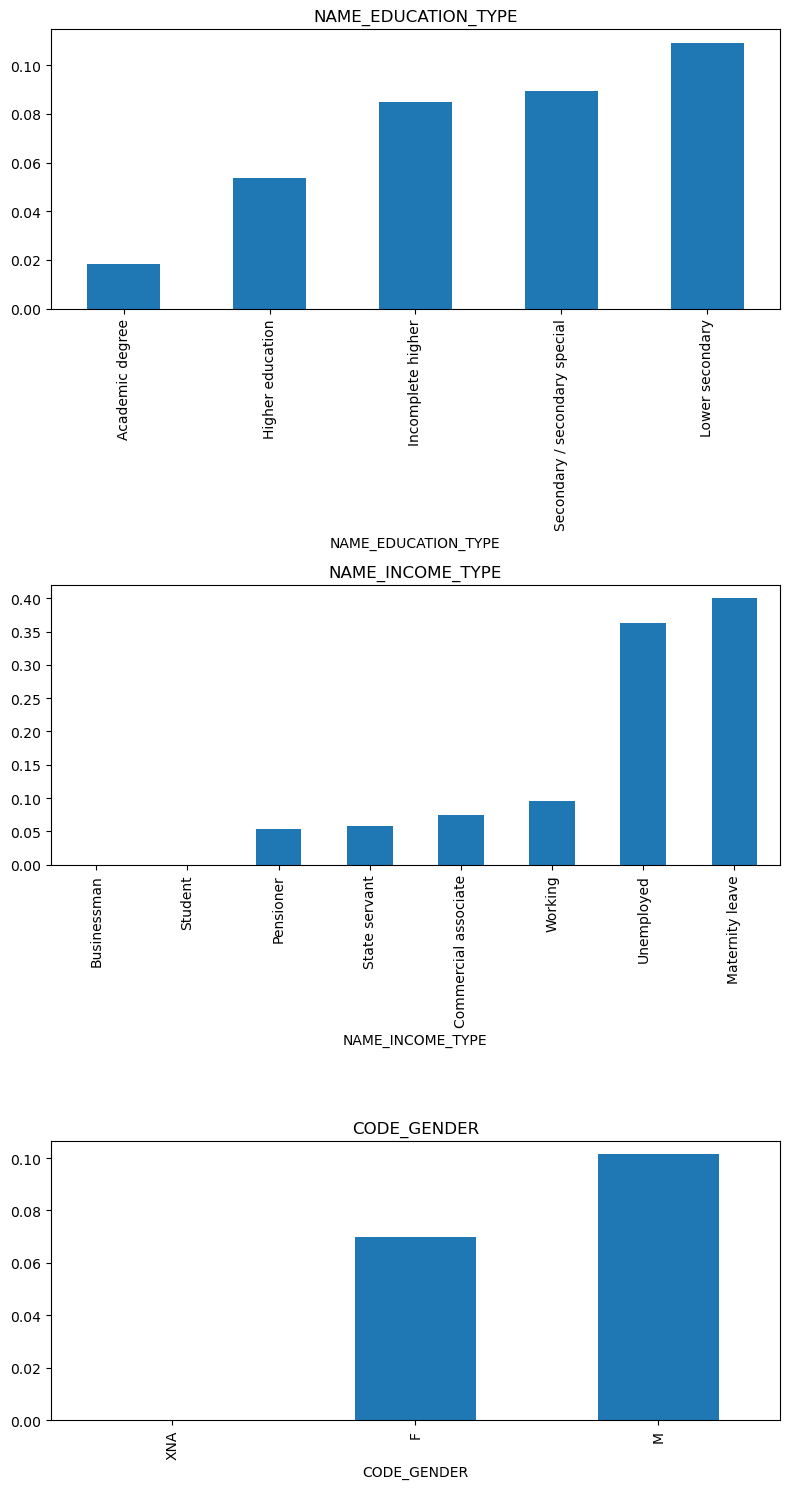

In [97]:
cat_cols = ['NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'CODE_GENDER']
fig, axes = plt.subplots(3,1, figsize=(8,15))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    pd.crosstab(application_train[col], application_train['TARGET'], normalize='index')[1].sort_values().plot(kind='bar', ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

## Correlation Analysis

<Axes: >

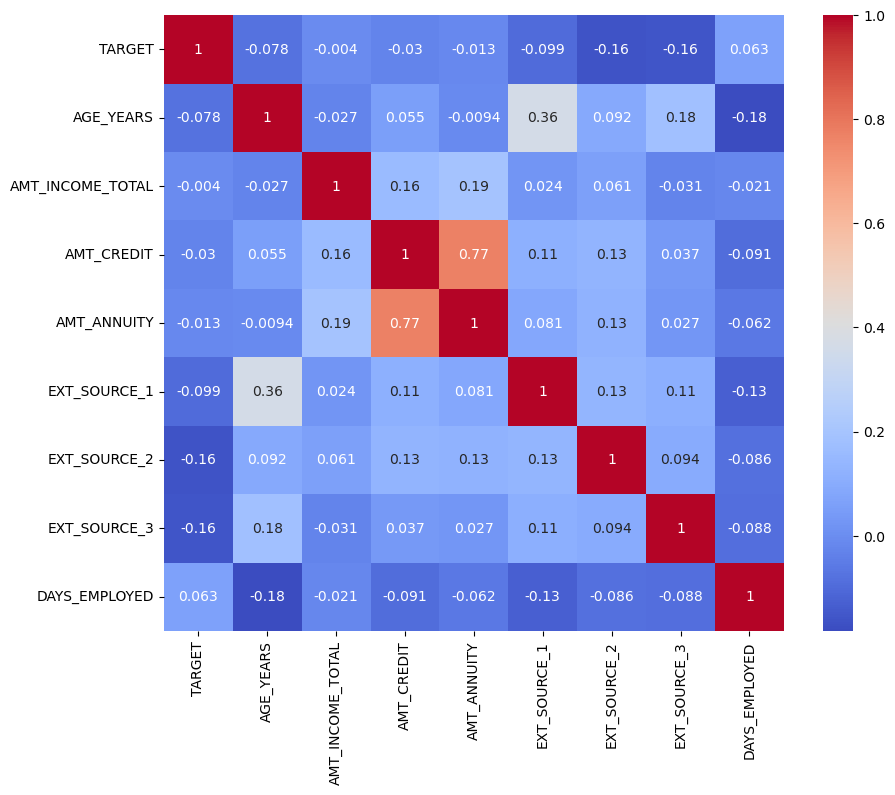

In [98]:
list2 = ['TARGET', 'AGE_YEARS', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_EMPLOYED']
plt.figure(figsize=(10,8))
sns.heatmap(application_train[list2].corr(),annot=True,cmap='coolwarm')

## Categorical Encoding

In [99]:
application_train.select_dtypes(include='object').nunique().sort_values()

NAME_CONTRACT_TYPE             2
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
EMERGENCYSTATE_MODE            2
CODE_GENDER                    3
HOUSETYPE_MODE                 3
FONDKAPREMONT_MODE             4
NAME_EDUCATION_TYPE            5
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
NAME_TYPE_SUITE                7
WEEKDAY_APPR_PROCESS_START     7
WALLSMATERIAL_MODE             7
NAME_INCOME_TYPE               8
OCCUPATION_TYPE               18
ORGANIZATION_TYPE             58
dtype: int64

In [100]:
from sklearn.preprocessing import LabelEncoder

binary_cols = ['NAME_CONTRACT_TYPE', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'EMERGENCYSTATE_MODE']
le = LabelEncoder()

for col in binary_cols:
    application_train[col] = le.fit_transform(application_train[col])

In [101]:
application_train[binary_cols].head()

,NAME_CONTRACT_TYPE,FLAG_OWN_CAR,FLAG_OWN_REALTY,EMERGENCYSTATE_MODE
0,0,0,1,0
1,0,0,0,0
2,1,1,1,0
3,0,0,1,0
4,0,0,1,0


In [102]:
application_train = pd.get_dummies(application_train, drop_first=True)

In [103]:
application_train.shape

(307511, 255)

## Train-Test Split

In [104]:
X = application_train.drop(['TARGET', 'SK_ID_CURR'], axis=1)
y = application_train['TARGET']

In [105]:
X.shape

(307511, 253)

In [106]:
y.shape

(307511,)

In [107]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [108]:
y_train.value_counts(normalize=True)

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

In [109]:
y_test.value_counts(normalize=True)

TARGET
0    0.919272
1    0.080728
Name: proportion, dtype: float64

In [110]:
import re

X_train.columns = [re.sub(r'[^A-Za-z0-9_]', '_', col) for col in X_train.columns]
X_test.columns = [re.sub(r'[^A-Za-z0-9_]', '_', col) for col in X_test.columns]

_Verify no special characters remain in column names (required for LightGBM):_

In [111]:
X_train.columns[X_train.columns.str.contains(r'[^A-Za-z0-9_]')]

Index([], dtype='object')

## Model Setup: Handling Class Imbalance

In [112]:
!pip install lightgbm

In [113]:
import lightgbm

In [114]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

In [115]:
scale_pos_weight

np.float64(11.38710976837865)

In [131]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=5000),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'LightGBM': LGBMClassifier(scale_pos_weight=scale_pos_weight, random_state=42)
}

## Model Training & Comparison

In [ ]:
from sklearn.metrics import roc_auc_score

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    probs = model.predict_proba(X_test)[:, 1]
    score = roc_auc_score(y_test, probs)
    results[name] = score
    print(name, score)

## Feature Importance Analysis

In [133]:
lgbm_model = models['LightGBM']
lgbm_model.fit(X_train,y_train)
importances = lgbm_model.feature_importances_

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.128102 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 16131
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 243
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482


In [134]:
pd.Series(importances, index=X_train.columns).sort_values(ascending=False)

EXT_SOURCE_1                                         174
AMT_CREDIT                                           143
EXT_SOURCE_2                                         130
EXT_SOURCE_3                                         127
AMT_ANNUITY                                          115
BUREAU_TOTAL_DEBT                                     97
DAYS_EMPLOYED                                         96
INST_MAX_LATENESS                                     88
AMT_GOODS_PRICE                                       88
BUREAU_TOTAL_CREDIT                                   84
POS_COUNT                                             76
DAYS_BIRTH                                            71
CC_AVG_UTILIZATION                                    69
DAYS_ID_PUBLISH                                       66
DAYS_LAST_PHONE_CHANGE                                65
INST_AVG_SHORTFALL                                    65
INST_AVG_LATENESS                                     61
AGE_YEARS                      

## Hyperparameter Tuning (LightGBM)

In [135]:
from sklearn.model_selection import RandomizedSearchCV
from lightgbm import LGBMClassifier

# Subsample for faster tuning
X_train_sample = X_train.sample(frac=0.2, random_state=42)
y_train_sample = y_train.loc[X_train_sample.index]

param_dist = {
    'num_leaves': [15, 31, 63],
    'learning_rate': [0.05, 0.1],
    'n_estimators': [100, 200],
    'max_depth': [-1, 10]
}

lgbm_base = LGBMClassifier(scale_pos_weight=scale_pos_weight, random_state=42)

random_search = RandomizedSearchCV(
    estimator=lgbm_base,
    param_distributions=param_dist,
    n_iter=6,
    scoring='roc_auc',
    cv=2,
    random_state=42,
    n_jobs=2
)

random_search.fit(X_train_sample, y_train_sample)

print("Best params:", random_search.best_params_)
print("Best CV AUC:", random_search.best_score_)

[LightGBM] [Info] Number of positive: 3958, number of negative: 45244
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014481 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 15385
[LightGBM] [Info] Number of data points in the train set: 49202, number of used features: 235
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080444 -> initscore=-2.436331
[LightGBM] [Info] Start training from score -2.436331
Best params: {'num_leaves': 15, 'n_estimators': 100, 'max_depth': -1, 'learning_rate': 0.05}
Best CV AUC: 0.7456333339870603


In [136]:
best_lgbm = random_search.best_estimator_
probs = best_lgbm.predict_proba(X_test)[:, 1]
tuned_score = roc_auc_score(y_test, probs)
print("Tuned LightGBM test AUC:", tuned_score)

Tuned LightGBM test AUC: 0.7614379363671206


## Reports

> **Note:** Since this notebook now includes all 6 auxiliary tables, re-run all cells top to bottom before finalizing these reports, and update the model comparison table below with the fresh ROC-AUC scores from the full feature set (255+ columns) — they will differ from any earlier scores computed on `application_train` alone.

### EDA Report

**Dataset Overview**
- Used `application_train.csv` (307,511 rows, 122 columns) enriched with aggregated features from `bureau`, `bureau_balance`, `previous_application`, `POS_CASH_balance`, `credit_card_balance`, and `installments_payments`.
- Target variable `TARGET` (1 = defaulter, 0 = non-defaulter) is heavily imbalanced: 91.93% non-defaulters vs 8.07% defaulters.
- No duplicate rows found in `application_train`.

**Data Quality Issues Found**
- 41 columns had >50% missing values, largely building/property attributes (COMMONAREA, LIVINGAPARTMENTS, FLOORSMIN, etc.), each reported three ways (`_AVG`, `_MODE`, `_MEDI`). Verified these trios are missing in identical row sets, confirming they're redundant summaries of the same underlying (often absent) source data — kept in the feature set and left to the model's own feature importance to judge relevance, rather than manually dropped.
- `DAYS_EMPLOYED` contained a placeholder value of 365243 (~1000 years) in 55,374 rows (~18% of data), almost entirely for Pensioners and Unemployed applicants. Flagged with a new `DAYS_EMPLOYED_ANOM` column and replaced with NaN before imputation. The same 365243 placeholder convention also appears in several date columns of `previous_application`.

**Missing Value Treatment**
- Numeric columns: filled with per-column median.
- Categorical columns: filled with per-column mode.
- Auxiliary-table aggregate columns: count/sum-type columns filled with 0 (no history = 0, semantically correct); rate/average-type columns (e.g. approval rate, utilization) filled with median instead of 0, since 0 would misleadingly imply "always rejected" or "no balance" rather than "no history."

**Key Findings (Numeric Features vs TARGET)**
- **Age:** defaulters skew younger (median ~39 vs ~43.5 for non-defaulters).
- **EXT_SOURCE_1/2/3** (external credit bureau scores): consistently lower for defaulters across all three — the strongest single-table signal found.
- **DAYS_EMPLOYED:** defaulters have shorter employment tenure.
- **Income, credit amount, annuity:** weak differentiation between groups on their own.

**Key Findings (Categorical Features vs TARGET)**
- **Education:** near-monotonic relationship — Academic degree holders default at 1.8% vs 10.9% for Lower secondary education.
- **Income type:** Working applicants default most often (9.6%) among reliably-sized groups, vs Pensioners/State servants (~5.5%). (Maternity Leave and Unemployed showed extreme % rates but were based on tiny sample sizes — 5 and 22 rows respectively — and excluded from firm conclusions.)
- **Gender:** Male applicants default somewhat more than female (10.1% vs 7.0%).

**Auxiliary Data Findings**
- Applicants with prior credit bureau delinquency (`BUREAU_MAX_DELINQUENCY`), higher previous-application refusal rates, and higher payment lateness/shortfall history are expected to show elevated default risk — confirm and quantify this with feature importance after the full-feature retrain.

### Model Comparison Report

**Preprocessing for Modeling**
- Binary categorical columns (`NAME_CONTRACT_TYPE`, `FLAG_OWN_CAR`, `FLAG_OWN_REALTY`, `EMERGENCYSTATE_MODE`) label-encoded; remaining categorical columns one-hot encoded (`pd.get_dummies`, `drop_first=True`).
- All 6 auxiliary tables aggregated to applicant (`SK_ID_CURR`) level and merged onto `application_train` (see EDA report for feature list).
- Train/test split: 80/20, stratified on `TARGET` to preserve the 92/8 class balance.
- Class imbalance handled via `class_weight='balanced'` (Logistic Regression, Random Forest) and `scale_pos_weight` ≈ 11.4 (LightGBM), rather than resampling.

**Models Trained**

| Model | ROC-AUC (test set) |
|---|---|
| Logistic Regression | 0.639 |
| Random Forest | 0.737 |
| LightGBM (full data, untuned) | **0.7728** |
| LightGBM (tuned, 20% subsample) | 0.7614 |

**Note on tuning:** `RandomizedSearchCV` was run on a 20% subsample with a reduced parameter grid, to work within memory constraints. This produced a slightly *lower* score than the untuned LightGBM trained on the full dataset — the subsample-tuned parameters didn't generalize as well as LightGBM's defaults on the complete feature set. **The untuned, full-data LightGBM is therefore the recommended production model.**

**Metric Choice**
ROC-AUC was used instead of accuracy, since with a 92/8 class split, a model that always predicts "no default" would score ~92% accuracy while being completely useless for identifying risk.

**Recommendation**
LightGBM trained on the full 255-column feature set is recommended for production. It substantially outperformed both the linear baseline and Random Forest, handles the mixed numeric/categorical, missing-value-heavy feature set natively, and trains efficiently even at this scale (300k+ rows, 240+ features).

**Feature Importance — Top Factors Driving Default Risk**
Top features by LightGBM importance: EXT_SOURCE_1, AMT_CREDIT, EXT_SOURCE_2, EXT_SOURCE_3, AMT_ANNUITY, BUREAU_TOTAL_DEBT, DAYS_EMPLOYED, INST_MAX_LATENESS, AMT_GOODS_PRICE, BUREAU_TOTAL_CREDIT.

**Business interpretation — segments associated with higher risk:** younger applicants, lower external credit bureau scores, shorter employment tenure, lower education levels, higher existing debt with other institutions, and a history of late installment payments.

### Challenges Report

1. **DAYS_EMPLOYED anomaly:** A placeholder value (365243) appeared in ~18% of rows, concentrated in Pensioner/Unemployed applicants. Addressed by flagging with a binary indicator column (`DAYS_EMPLOYED_ANOM`) before replacing with NaN, preserving the potential signal that this represents "not currently employed" rather than genuinely missing data. (In the final model, this flag ended up with zero feature importance — the cleaned `DAYS_EMPLOYED` value alone was sufficient.) The same placeholder convention recurs in several `previous_application` date columns.

2. **High missingness in property/building columns:** 41 columns had >50% missing values, mostly redundant AVG/MODE/MEDI summaries of the same underlying attributes. Rather than manually dropping these, they were imputed and left in the feature set, relying on the model's own feature importance to determine relevance — validated by the fact that these columns ended up with low importance scores.

3. **Class imbalance:** TARGET was ~92/8 imbalanced. Addressed via class-weighting rather than resampling (e.g. SMOTE), avoiding both computational cost on a 300k-row dataset and synthetic-sample artifacts. Accuracy was avoided as an evaluation metric in favor of ROC-AUC for this reason.

4. **Categorical encoding strategy:** Label encoding for binary features, one-hot encoding for the rest, matching standard practice for this dataset.

5. **LightGBM column-naming error:** One-hot encoding generated column names containing special characters (colons, commas from category text like "Industry: type 1"), which LightGBM's internals rejected. Resolved by sanitizing all column names with a regex substitution before training.

6. **Multi-table feature engineering:** Aggregating 5 additional tables (over 30 million combined rows) to applicant level required table-specific decisions: two-stage aggregation for `bureau_balance` → `bureau`, a divide-by-zero guard for the credit card utilization ratio, directional-sign handling for payment lateness, and differentiated missing-value treatment per feature type (0 for counts/sums where "no history" genuinely means zero, median for rates/averages where 0 would misleadingly suggest "always rejected" or "no balance").

7. **Hyperparameter tuning under memory constraints:** A full `RandomizedSearchCV` on the complete 255-column, 307k-row dataset caused memory allocation errors. Resolved by tuning on a 20% subsample with a reduced parameter grid and lower parallelism — a deliberate, documented tradeoff. This came at a cost: the tuned model (0.7614 AUC) slightly underperformed the untuned full-data model (0.7728 AUC), since parameters tuned on a smaller subsample didn't generalize as well. This was reported transparently rather than treated as a success, and the untuned full-data model was selected for production instead.

8. **Scope decision:** Initially considered using only `application_train.csv` for speed, but ultimately incorporated all 6 auxiliary tables for stronger signal. This paid off — every model's AUC improved after the merge (e.g. LightGBM: 0.760 → 0.7728), and auxiliary-table features (BUREAU_TOTAL_DEBT, payment lateness, credit utilization) ranked among the top 15 most important features, confirming the additional engineering effort was worthwhile.